# 06 · "The four functions": the final map

A rectangle whose four corners are four functions of the passages (from `03_functions.ipynb`):
interiorise (top left), regulate (top right), venerate (bottom left) and legitimise (bottom right).
Each passage, topic and work sits closer to the corners whose function it fulfils more.

- **Topics** (spaced capitals): groups of similar passages found automatically (`02_map.ipynb`),
  placed at the average position of their passages.
- **Works** (colored balls): color = religious order of the author; size = editions printed in Spanish,
  1500–1800, in the catalogue of the Biblioteca Nacional de España (`04_editions.ipynb`).
- **Background**: where passages rich in the language of the senses gather (`05_senses.ipynb`).

The plane is stretched so that passages cover the rectangle evenly: positions are relative.
This is an exploration, not a final result.

Input (in `DATA_DIR`): `passages.csv.gz`, `functions_soft.csv.gz`, `uniform_xy.csv.gz`, `texts.csv`,
`editions.csv`, `themes.json`. Output: a PNG and a PDF in `FIGURES_DIR`.

## 1. Settings

In [1]:
DATA_DIR = "../data/results"     # folder with the data files (see the README)
FONTS_DIR = "../fonts"           # Lato and Lora (free fonts, included in the repository)
FIGURES_DIR = "../figures"       # where the figure is saved
LANG = "en"                      # "en" or "es"
FORMAT = "half"                  # "a4": 24.7 × 14.5 cm; "half": half an A4 page, 16 × 13 cm; "phone": 9 × 20 cm

In [2]:
import os, json, textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager, patheffects
from matplotlib.colors import to_rgb
from scipy.ndimage import gaussian_filter
from scipy.spatial import cKDTree

for name in ["Lato-Regular.ttf", "Lato-Bold.ttf", "Lora-Regular.ttf", "Lora-Italic.ttf"]:
    font_manager.fontManager.addfont(f"{FONTS_DIR}/{name}")
SANS, LORA = "Lato", "Lora"
INK, MUTED = "#1d1d1b", "#6f6a60"
plt.rcParams.update({"font.family": SANS})
os.makedirs(FIGURES_DIR, exist_ok=True)

## 2. Topics and works on the diamond

First everything is placed on a diamond: one corner per function, and each point is the average of the
four corners weighted by its function percentages. Example: 25 % of each function -> the center (0, 0);
100 % interiorise -> the top corner (0, 1).

In [3]:
FUNCTIONS = ["legitimar", "devocion", "normar", "interiorizar"]
CORNER = {"interiorizar": (0, 1), "legitimar": (0, -1), "devocion": (-1, 0), "normar": (1, 0)}

def position(table):
    """Weighted average of the four corners (weights = function percentages)."""
    return sum(np.outer(table[f], CORNER[f]) for f in FUNCTIONS)

soft = pd.read_csv(f"{DATA_DIR}/functions_soft.csv.gz")
passages = pd.read_csv(f"{DATA_DIR}/passages.csv.gz",
                       usecols=["text_id", "chunk_n", "cluster", "order_group", "title", "author", "year"])
data = soft.merge(passages)
themes = json.load(open(f"{DATA_DIR}/themes.json", encoding="utf-8"))
labels = {int(k): v for k, v in themes[LANG].items()}

# Topics: mean percentages of their passages (cluster -1 = passages in no topic)
topics = data[data["cluster"] >= 0].groupby("cluster")[FUNCTIONS].mean()
topics[["x", "y"]] = position(topics)
topics["n"] = data[data["cluster"] >= 0].groupby("cluster").size()

# Works: "Author | Title" (volumes of one work together), mean percentages of their passages
data["work"] = data["author"].str.split(";").str[0].str.split("(").str[0].str.strip() + " | " + data["title"]
books = data.groupby("work").agg(**{f: (f, "mean") for f in FUNCTIONS}, title=("title", "first"),
                                 order=("order_group", "first"), year=("year", "min"))
books[["x", "y"]] = position(books)
GROUP = {"Jesuita": "Jesuitas", "Dominico": "Dominicos", "Franciscano": "Familia franciscana",
         "Concepcionista": "Familia franciscana", "Carmelita": "Carmelitas"}
books["group"] = books["order"].map(GROUP).fillna("Otros")

# Editions of each work (from 04_editions.ipynb)
work_ids = data.groupby("work")["text_id"].first().map(pd.read_csv(f"{DATA_DIR}/texts.csv").set_index("text_id")["work_id"])
books["editions"] = work_ids.map(pd.read_csv(f"{DATA_DIR}/editions.csv", index_col="work_id")["editions"]).reindex(books.index).fillna(0)
print(len(topics), "topics,", len(books), "works")

92 topics, 123 works


## 3. From the diamond to the rectangle

The diamond is turned 45°: (x, y) -> (x − y, x + y). Then it is stretched so that passages cover the
rectangle evenly (`05_senses.ipynb` saved the stretched position of every passage). Topics and works move
with the passages around them: each one goes to the mean stretched position of its 50 nearest passages.

In [4]:
def rotate(xy):
    """Diamond coordinates -> rectangle coordinates. Example: interiorizar (0, 1) -> (-1, 1), top-left."""
    xy = np.asarray(xy)
    return np.column_stack([xy[:, 0] - xy[:, 1], xy[:, 0] + xy[:, 1]])

stretched = pd.read_csv(f"{DATA_DIR}/uniform_xy.csv.gz")
PASSAGE_XY = stretched[["uniform_u", "uniform_v"]].to_numpy()
SENSORY_FLAG = stretched["sensory"].astype(float).to_numpy()
tree = cKDTree(stretched[["u", "v"]].to_numpy())

def stretch(points):
    """Example: a topic at (-0.6, 0.2) -> about (-0.45, 0.25)."""
    _, nearest = tree.query(points.to_numpy(), k=50)
    return pd.DataFrame(PASSAGE_XY[nearest].mean(axis=1), index=points.index, columns=["u", "v"])

topic_xy = stretch(pd.DataFrame(rotate(topics[["x", "y"]]), index=topics.index, columns=["u", "v"]))
book_xy = stretch(pd.DataFrame(rotate(books[["x", "y"]]), index=books.index, columns=["u", "v"]))
CORNERS = {"interiorizar": (-1, 1), "normar": (1, 1), "devocion": (-1, -1), "legitimar": (1, -1)}

## 4. Page sizes, colors and words

Point sizes are the real ones on paper at each format.

In [5]:
CM = 1 / 2.54
# Corner names, glosses, legend, scale words, scale caption, reading notes, topics (smallest, largest),
# work titles and authors; ball area factor; resolution
SIZES = {
    "a4":    dict(page=(24.7, 14.5), name=10, gloss=6.5, legend=5.4, scale=6.5, caption=6, notes=6,
                  topics=(3.5, 5.0), title=6.3, author=5.3, balls=1.0, dpi=300),
    "half":  dict(page=(16.0, 13.0), name=9, gloss=6, legend=5.4, scale=6, caption=6, notes=6,
                  topics=(3.0, 4.3), title=5.6, author=4.8, balls=0.6, dpi=300),
    "phone": dict(page=(9.0, 20.0), name=12, gloss=7.5, legend=6.5, scale=7.5, caption=7, notes=7.5,
                  topics=(5.5, 7.5), title=8, author=6.8, balls=1.0, dpi=400),
}[FORMAT]
FIG_W, FIG_H = SIZES["page"][0] * CM, SIZES["page"][1] * CM
MAX_SHIFT = 0.36                               # a topic name may move at most this far from its true spot
FONT_MIN, FONT_MAX = SIZES["topics"]

def pt_x(points):
    """Horizontal distance in points -> figure fraction."""
    return points / 72 / FIG_W

def points_to_fig_y(points):
    """Vertical distance in points -> figure fraction. Example: 10 pt ≈ 0.0175 of an A4 page's height."""
    return points / 72 / FIG_H

# Map area in figure fractions. half/phone: room (points) above and below for names, legends and notes
MARGIN_TOP, MARGIN_BOTTOM = {"a4": (0, 0), "half": (38, 30), "phone": (76, 182)}[FORMAT]
MAP_RECT = [0.008, 0.075, 0.984, 0.835] if FORMAT == "a4" else \
    [0.008, MARGIN_BOTTOM / 72 / FIG_H, 0.984, 1 - (MARGIN_TOP + MARGIN_BOTTOM) / 72 / FIG_H]

In [6]:
# Order colors, and darker versions of them for names of works and their arrows (they must read over carmine)
ORDER_COLORS = {"Jesuitas": "#1f9a4e", "Dominicos": "#2563c9", "Carmelitas": "#8a5523",
                "Familia franciscana": "#e8a317", "Otros": "#a8a29a"}
TEXT_COLORS = {"Jesuitas": "#0e5a2e", "Dominicos": "#173f80", "Carmelitas": "#5a3512",
               "Familia franciscana": "#7d5200", "Otros": "#4f4a43"}
SENSORY_PAPER, SENSORY_COLOR = "#efe4d0", "#a8343f"   # paper -> carmine

def sensory_tint(t):
    """t from 0 (not sensory) to 1 (very sensory) -> color. Example: t = 0 -> paper."""
    t = np.clip(t, 0, 1)[..., None] ** 1.3 * 0.78        # 0.78: the strongest areas stop short of full carmine
    paper, carmine = np.array(to_rgb(SENSORY_PAPER)), np.array(to_rgb(SENSORY_COLOR))
    return paper + t * (carmine - paper)

# Works named on the map ("Author | Title" -> title and author as printed)
LABELED = {
    "Tomás de Kempis | Contemptus mundi": ("Contemptus mundi", "Tomás de Kempis"),
    "Ignacio de Loyola | Ejercicios espirituales": ("Ejercicios espirituales", "Ignacio de Loyola"),
    "Teresa de Ávila | Las Moradas o Castillo interior": ("Las Moradas", "Teresa de Jesús"),
    "Luis de Granada | Guía de pecadores": ("Guía de pecadores", "Luis de Granada"),
    "Juan de la Cruz | Cántico espiritual": ("Cántico espiritual", "Juan de la Cruz"),
    "Francisco de Sales | Introducción a la vida devota": ("Introducción a la vida devota", "Francisco de Sales"),
    "Teresa de Ávila | Cartas": ("Cartas", "Teresa de Jesús"),
    "Teresa de Ávila | Libro de las Fundaciones": ("Libro de las Fundaciones", "Teresa de Jesús"),
    "Teresa de Ávila | Constituciones": ("Constituciones", "Teresa de Jesús"),
    "Antonio Guevara | Epístolas familiares": ("Epístolas familiares", "Antonio de Guevara"),
    "Juan Martínez de la Parra | Luz de verdades católicas": ("Luz de verdades católicas", "Juan Martínez de la Parra"),
    "María de Jesús de Ágreda | Mística Ciudad de Dios": ("Mística Ciudad de Dios", "María de Jesús de Ágreda"),
    "Luis de Granada | Libro de la oración y meditación": ("Libro de la oración y meditación", "Luis de Granada"),
}
if FORMAT == "phone":                          # on the phone, only the canon
    CANON = {"Ejercicios espirituales", "Las Moradas", "Cántico espiritual", "Guía de pecadores",
             "Introducción a la vida devota", "Libro de las Fundaciones"}
    LABELED = {k: v for k, v in LABELED.items() if v[0] in CANON}
# Authors with an established English name (the others keep their Spanish name, as in English scholarship)
AUTHORS_EN = {"Ignacio de Loyola": "Ignatius of Loyola", "Teresa de Jesús": "Teresa of Ávila",
              "Juan de la Cruz": "John of the Cross", "Francisco de Sales": "Francis de Sales"}

In [7]:
# Words of the figure in each language. Titles of works are never translated.
WORDS = {
    "es": {"names": {"interiorizar": "Interiorizar", "normar": "Normar", "devocion": "Venerar", "legitimar": "Legitimar"},
           "glosses": {"interiorizar": "oración, vida mística, unión con Dios", "normar": "pecados, reglas, confesión",
                       "devocion": "Pasión, Virgen, misa", "legitimar": "fundaciones, misiones, mártires"},
           "sensory_scale": "Intensidad según vocabularios controlados de palabras del campo semántico de lo sensorial: ojos, luz, voz, oír, etc.",
           "sensory_low": "poco sensorial", "sensory_high": "muy sensorial",
           # Reading notes inside the map (a4 only): (u, v, horizontal alignment, text, leader line or None)
           "notes": [
               (-0.980, 0.980, "left", "Cada esquina es una función: cuanto más\ncerca, más la cumple el fragmento. Identifiqué\n"
                                       "las cuatro funciones con un algoritmo (k-means)\ntras descontar si el texto narra o prescribe.", None),
               (0.213, 0.966, "left", "En versalitas, los temas: grupos de fragmentos\nparecidos que detecté de forma automática\n"
                                      "y luego nombré.", ((0.210, 0.815), (0.188, 0.700))),
               (0.984, 0.980, "right", "El mapa ubica fragmentos de 250 palabras.\nLo estiré para que ocupe todo el rectángulo:\n"
                                       "las posiciones son relativas.", None),
           ],
           "orders": {"Familia franciscana": "Franciscanos"}, "editions": "ediciones (BNE, 1500–1800)"},
    "en": {"names": {"interiorizar": "Interiorise", "normar": "Regulate", "devocion": "Venerate", "legitimar": "Legitimise"},
           "glosses": {"interiorizar": "prayer, mystical life, union with God", "normar": "sins, rules, confession",
                       "devocion": "Passion, Virgin, Mass", "legitimar": "foundations, missions, martyrs"},
           "sensory_scale": "Language of the senses: passages richest in sight, hearing, smell, taste or touch. Relative positions",
           "sensory_low": "less sensory", "sensory_high": "more sensory",
           "notes": [],
           "orders": {"Jesuitas": "Jesuits", "Dominicos": "Dominicans", "Carmelitas": "Carmelites",
                      "Familia franciscana": "Franciscans", "Otros": "Others"},
           "editions": "editions (BNE, 1500–1800)"},
}[LANG]

def circle_size(editions):
    """Ball area in points². Example (a4): 1 edition → 15, 10 → 96, 30 → 276."""
    return (6 + 9 * editions) * SIZES["balls"]

def topic_font(n):
    """Bigger topics (more passages) get bigger names."""
    return FONT_MIN + (FONT_MAX - FONT_MIN) * np.sqrt(n / topics["n"].max())

def spaced_caps(name):
    """'Gobierno real' -> 'G O B I E R N O   R E A L' (atlas lettering).
    Letters are joined by a hair space (\\u200a), words by an en space (\\u2002)."""
    return " ".join(" ".join(word.upper()) for word in name.split())

## 5. Background: where sensory passages gather

On a 320 × 320 grid: the local share of sensory passages, smoothed. The 10 % least sensory areas stay as
paper, the 2 % most sensory take the strongest carmine. Opacity follows how many passages live there.

In [8]:
def draw_background(ax):
    pts = PASSAGE_XY
    grid = 320
    edges = np.linspace(-1, 1, grid + 1)
    count = gaussian_filter(np.histogram2d(pts[:, 0], pts[:, 1], bins=[edges, edges])[0].T, 7)
    hits = gaussian_filter(np.histogram2d(pts[:, 0], pts[:, 1], bins=[edges, edges], weights=SENSORY_FLAG)[0].T, 7)
    share = hits / np.maximum(count, 1e-9)
    low, high = np.quantile(share[count > 0.05], [0.10, 0.98])
    wash = sensory_tint((share - low) / (high - low))
    alpha = np.clip(np.sqrt(count / np.quantile(count[count > 0], 0.97)), 0, 1) * 0.72
    grain = gaussian_filter(np.random.default_rng(3).normal(0, 1, count.shape), 1.6)   # a little watercolor grain
    alpha = np.clip(alpha * (1 + 0.22 * grain / grain.std()), 0, 0.82)
    ax.imshow(np.dstack([wash, alpha]), origin="lower", extent=(-1, 1, -1, 1), interpolation="bicubic",
              aspect="auto", zorder=0.5)
    ax.plot([-1, 1, 1, -1, -1], [-1, -1, 1, 1, -1], color=MUTED, lw=0.5, zorder=1.2)

## 6. Measuring text in map units

In [9]:
def measure(fig, ax, text, **font):
    """Half width and half height of a text box, in map units."""
    t = ax.text(0, 0, text, **font)
    b = t.get_window_extent(fig.canvas.get_renderer())
    (x0, y0), (x1, y1) = ax.transData.inverted().transform([(b.x0, b.y0), (b.x1, b.y1)])
    t.remove()
    return (x1 - x0) / 2, (y1 - y0) / 2

def units_per_point(fig, ax):
    box = ax.get_window_extent()
    return 2 / (box.width * 72 / fig.dpi), 2 / (box.height * 72 / fig.dpi)

def overlaps(u, v, hw, hh, boxes):
    return any(abs(u - bu) < hw + bw and abs(v - bv) < hh + bh for bu, bv, bw, bh in boxes)

def radius(book):
    """Radius of a book's circle, in points."""
    return np.sqrt(circle_size(books.loc[book, "editions"]) / np.pi)

def curve(start, end, rad, up, vp, n=14):
    """Points along matplotlib's arc3 curve from start to end (computed in points, returned in map units)."""
    (x1, y1), (x2, y2) = (start[0] / up, start[1] / vp), (end[0] / up, end[1] / vp)
    cx, cy = (x1 + x2) / 2 + rad * (y2 - y1), (y1 + y2) / 2 - rad * (x2 - x1)
    t = np.linspace(0.1, 0.95, n)[:, None]
    pts = (1 - t) ** 2 * np.array([x1, y1]) + 2 * (1 - t) * t * np.array([cx, cy]) + t ** 2 * np.array([x2, y2])
    return pts * np.array([up, vp])

## 7. Named works: title, author and year beside the book, joined by a curved arrow

For each named work, the free spot near it that covers the fewest topics and whose arrow crosses the fewest
topics, books and other names.

In [10]:
def labeled_books():
    names = AUTHORS_EN if LANG == "en" else {}
    return [(work, title, names.get(author, author)) for work, (title, author) in LABELED.items() if work in books.index]

def arrow_geometry(book, u, v, hw, up, vp):
    """Start of the arrow (the book), its end (the middle of the side of the name nearest to the book) and its bend."""
    bu, bv = book_xy.loc[book]
    k = SIZES["title"] / 6.3
    sides = [(u, v + 9 * k * vp), (u, v - 8 * k * vp), (u - hw, v), (u + hw, v)]  # top, bottom, left, right
    end = min(sides, key=lambda p: ((p[0] - bu) / up) ** 2 + ((p[1] - bv) / vp) ** 2)
    bend = 0.25 if (bu > end[0]) == (bv < end[1]) else -0.25                     # bulge away from the text
    return (bu, bv), end, -bend

def place_labels(fig, ax, found):
    fig.canvas.draw()
    up, vp = units_per_point(fig, ax)
    circles = book_xy.to_numpy()
    radii = np.sqrt(circle_size(books["editions"].to_numpy()) / np.pi) + 1
    topic_pts = topic_xy.to_numpy()
    boxes, where, paths = [], {}, []
    for book, title, author in found:
        hw, hh = measure(fig, ax, f"{title}\n{author}, 1600", fontfamily=LORA, fontsize=SIZES["title"], linespacing=1.25)
        hw, hh = hw + 3 * up, hh + 2 * vp
        u0, v0 = book_xy.loc[book]
        best = None
        for distance, strict in [(d, True) for d in (0.14, 0.19, 0.25, 0.32, 0.40, 0.50, 0.62, 0.75)] + [(d, False) for d in (0.25, 0.40, 0.55)]:
            if best is not None and not strict:
                break                                                 # second pass only if nothing fitted
            for angle in np.linspace(0, 2 * np.pi, 24, endpoint=False):
                u, v = u0 + distance * np.cos(angle), v0 + distance * 0.9 * np.sin(angle)
                if abs(u) + hw > 0.98 or abs(v) + hh > 0.97 or overlaps(u, v, hw, hh, boxes):
                    continue
                if strict and np.any((np.abs(circles[:, 0] - u) < hw + radii * up) & (np.abs(circles[:, 1] - v) < hh + radii * vp)):
                    continue
                covered = ((np.abs(topic_pts[:, 0] - u) < hw) & (np.abs(topic_pts[:, 1] - v) < hh)).sum()
                start, end, rad = arrow_geometry(book, u, v, hw - 3 * up, up, vp)
                line = curve(start, end, rad, up, vp)
                near_topics = sum(((np.abs(topic_pts[:, 0] - pu) < 0.05) & (np.abs(topic_pts[:, 1] - pv) < 0.02)).any()
                                  for pu, pv in line)
                near_books = sum(((np.abs(circles[:, 0] - pu) < radii * up) & (np.abs(circles[:, 1] - pv) < radii * vp)).sum()
                                 for pu, pv in line[2:])
                crossings = sum(overlaps(pu, pv, 0, 0, boxes) for pu, pv in line)
                on_arrows = sum(abs(u - pu) < hw and abs(v - pv) < hh for pu, pv, _, _ in paths)
                score = 2 * covered + near_topics + near_books + 4 * crossings + 4 * on_arrows + 6 * distance
                if best is None or score < best[0]:
                    best = (score, u, v, line)
        where[book] = (best[1], best[2], hw - 3 * up)
        boxes.append((best[1], best[2], hw, hh))
        paths.extend((pu, pv, 2 * up, 2 * vp) for pu, pv in best[3])      # arrows are obstacles for topic names
    return where, boxes + paths

def draw_labels(fig, ax, found, where):
    up, vp = units_per_point(fig, ax)
    for book, title, author in found:
        u, v, hw = where[book]
        color = TEXT_COLORS[books.loc[book, "group"]]                 # name and arrow in the color of the order
        halo = [patheffects.withStroke(linewidth=2.2, foreground="white", alpha=0.85)] if FORMAT == "phone" else None
        ax.text(u, v, title, fontfamily=LORA, fontstyle="italic", fontsize=SIZES["title"], color=color, ha="center", va="bottom", zorder=7, path_effects=halo)
        ax.text(u, v, f"{author}, {int(books.loc[book, 'year'])}", fontfamily=LORA,
                fontsize=SIZES["author"], color=color, ha="center", va="top", zorder=7, path_effects=halo)
        start, end, rad = arrow_geometry(book, u, v, hw, up, vp)
        # Arrow from the edge of the ball to the name:
        ax.annotate("", xy=end, xytext=start, zorder=7,
                    arrowprops=dict(arrowstyle="-|>,head_length=0.35,head_width=0.18", color=color, lw=0.45,
                                    shrinkA=radius(book), shrinkB=1, connectionstyle=f"arc3,rad={rad}"))

## 8. Topic names and works

Topic names: biggest topics first, each in the free spot nearest to its true position (a spiral search);
books, names of works and arrows are obstacles. A name with no room nearby is left out and printed.

In [11]:
def place_topics(fig, ax, fixed):
    fig.canvas.draw()
    up, vp = units_per_point(fig, ax)
    half_w, half_h = [], []
    for cluster in topics.index:
        hw, hh = measure(fig, ax, spaced_caps(labels[cluster]), fontfamily=SANS, fontsize=topic_font(topics.loc[cluster, "n"]))
        half_w.append(hw + 2 * up); half_h.append(hh + 1.5 * vp)
    circles = book_xy.to_numpy()
    r_pt = np.sqrt(circle_size(books["editions"].to_numpy()) / np.pi) * 0.8      # big balls may be grazed a little
    ru, rv = r_pt * up, r_pt * vp

    def fits(u, v, i, placed):
        if abs(u) + half_w[i] > 0.985 or abs(v) + half_h[i] > 0.985:
            return False
        if np.any((np.abs(circles[:, 0] - u) < half_w[i] + ru) & (np.abs(circles[:, 1] - v) < half_h[i] + rv)):
            return False
        return not overlaps(u, v, half_w[i], half_h[i], placed)

    spiral = [(r * np.cos(a), 0.6 * r * np.sin(a)) for r in np.arange(0, MAX_SHIFT, 0.003)
              for a in np.linspace(0, 2 * np.pi, 48, endpoint=False)]
    placed, where = list(fixed), {}
    for i in np.argsort(-topics["n"].to_numpy()):
        cluster = topics.index[i]
        u0, v0 = topic_xy.loc[cluster]
        spot = next(((u0 + du, v0 + dv) for du, dv in spiral if fits(u0 + du, v0 + dv, i, placed)), None)
        if spot is None:
            print("no room for", labels[cluster]); continue
        where[cluster] = spot
        placed.append((*spot, half_w[i], half_h[i]))
    return where

def draw_topics(ax, where):
    for cluster, (u, v) in where.items():
        ax.text(u, v, spaced_caps(labels[cluster]), fontfamily=SANS, fontsize=topic_font(topics.loc[cluster, "n"]),
                color=INK, ha="center", va="center", zorder=4)

def draw_books(ax):
    # Biggest first, so small balls stay visible on top:
    for book, b in books.sort_values("editions", ascending=False).iterrows():
        ax.scatter(*book_xy.loc[book], s=circle_size(b["editions"]), color=ORDER_COLORS[b["group"]],
                   alpha=0.75, edgecolor="white", linewidth=0.4, zorder=3)

## 9. Corners

A dot on each vertex and an arrow from it to the name (it leaves vertical and arrives horizontal, at the
middle of the capitals of the name). The gloss beside the name is centered on that same line.

In [12]:
CAP_LORA, CAP_LATO = 0.70, 0.72                   # cap height as a share of the font size

def corner_lines():
    """Baseline of the corner names above and below the map, and the middle line of their capitals."""
    left, bottom, width, height = MAP_RECT
    top = bottom + height
    if FORMAT == "a4":
        top_base, bottom_base = top + 0.025, bottom - 0.045
    elif FORMAT == "half":
        top_base, bottom_base = top + points_to_fig_y(8), bottom - points_to_fig_y(16)
    else:                                          # phone: the gloss goes between the upper names and the map
        top_base, bottom_base = top + points_to_fig_y(18), bottom - points_to_fig_y(16)
    half = points_to_fig_y(CAP_LORA * SIZES["name"] / 2)
    return {"top": (top_base, top_base + half), "bottom": (bottom_base, bottom_base + half)}

def draw_corners(fig, ax):
    left, bottom, width, height = MAP_RECT
    inset = 0.045
    lines = corner_lines()
    spots = {"interiorizar": (left + inset, "top", "left"), "normar": (left + width - inset, "top", "right"),
             "devocion": (left + inset, "bottom", "left"), "legitimar": (left + width - inset, "bottom", "right")}
    ends = {}
    for f, (x, side, ha) in spots.items():
        base_y, middle = lines[side]
        cu, cv = CORNERS[f]
        ax.scatter(cu, cv, s=14, color=INK, zorder=8, clip_on=False)
        t = fig.text(x, base_y, WORDS["names"][f], fontfamily=LORA, fontsize=SIZES["name"], color=INK, ha=ha, va="baseline")
        fig.canvas.draw()
        w = t.get_window_extent(fig.canvas.get_renderer()).width / fig.bbox.width
        if FORMAT == "phone":                    # gloss under the name, aligned with it
            gx, gloss_base = x, base_y - points_to_fig_y(11)
        else:                                    # gloss beside the name, centered on its capitals
            gx = x + w + 0.008 if ha == "left" else x - w - 0.008
            gloss_base = middle - points_to_fig_y(CAP_LATO * SIZES["gloss"] / 2)
        g = fig.text(gx, gloss_base, WORDS["glosses"][f], fontfamily=SANS, fontsize=SIZES["gloss"], color=MUTED, ha=ha, va="baseline")
        fig.canvas.draw()
        gw = g.get_window_extent(fig.canvas.get_renderer()).width / fig.bbox.width
        ends[f] = gx + gw if ha == "left" else gx - gw                 # where the gloss ends (free space after it)
        anchor = (x - 0.004 if ha == "left" else x + 0.004, middle)
        anchor = ax.transData.inverted().transform(fig.transFigure.transform(anchor))   # in map units
        ax.annotate("", xy=anchor, xycoords="data", xytext=(cu, cv), textcoords="data", zorder=8,
                    annotation_clip=False,
                    arrowprops=dict(arrowstyle="-|>,head_length=0.35,head_width=0.18", color=INK, lw=0.5,
                                    shrinkA=2.5, shrinkB=1, connectionstyle="angle3,angleA=90,angleB=0"))
    return ends

## 10. Legends

Bottom: the background scale, between the lower corner names. Top: orders and sizes, in one line
(two lines on the phone), centered on the page.

In [13]:
def text_width(fig, text, **font):
    """Width of a text in figure fraction (drawn invisibly, measured, removed)."""
    t = fig.text(0, 0, text, **font)
    fig.canvas.draw()
    w = t.get_window_extent(fig.canvas.get_renderer()).width / fig.bbox.width
    t.remove()
    return w

def dot_width(area):
    return 2 * np.sqrt(area / np.pi) / 72 / FIG_W

def dot(fig, x, y, area, color):
    """A circle of the given area (points²) whose left edge is at x and center at height y."""
    diameter = 2 * np.sqrt(area / np.pi)
    fig.lines.append(plt.Line2D([x + dot_width(area) / 2], [y], marker="o", markersize=diameter, color=color,
                                alpha=0.75, markeredgecolor="white", markeredgewidth=0.4, transform=fig.transFigure))

def draw_scale(fig, ends):
    """Gradient bar with its two end words; a4 and phone also get a caption under it."""
    lines = corner_lines()
    scale_font = SIZES["scale"]
    bar_y = lines["bottom"][1]
    bar_w = {"a4": 0.16, "half": 0.11, "phone": 0.30}[FORMAT]
    middle_x = (ends["devocion"] + ends["legitimar"]) / 2
    if FORMAT == "phone":                            # its own line, under the lower glosses
        bar_y, middle_x = lines["bottom"][0] - points_to_fig_y(27), 0.5
    x = middle_x - bar_w / 2
    bar_h = 0.014 if FORMAT == "a4" else points_to_fig_y(5.75 * scale_font / 6.5)
    bar = fig.add_axes([x, bar_y - bar_h / 2, bar_w, bar_h]); bar.axis("off")
    word_base = bar_y - points_to_fig_y(CAP_LORA * scale_font / 2)
    bar.imshow(sensory_tint(np.linspace(1, 0, 200))[None, :, :], aspect="auto")    # very sensory on the left
    fig.text(x - 0.005, word_base, WORDS["sensory_high"], fontfamily=LORA, fontsize=scale_font, color=SENSORY_COLOR, ha="right", va="baseline")
    fig.text(x + bar_w + 0.005, word_base, WORDS["sensory_low"], fontfamily=LORA, fontsize=scale_font, color=MUTED, ha="left", va="baseline")
    if FORMAT != "half":                             # half: the explanation goes in the caption of the figure
        gap, text = {"a4": (0.028, WORDS["sensory_scale"]),
                     "phone": (points_to_fig_y(9), textwrap.fill(WORDS["sensory_scale"], 56))}[FORMAT]
        fig.text(middle_x, bar_y - gap, text, fontfamily=SANS, fontsize=SIZES["caption"], color=MUTED, ha="center",
                 va="top" if FORMAT == "phone" else "baseline", linespacing=1.25)

def draw_key(fig, ends):
    """Orders and sizes: pieces measured first, then drawn centered."""
    size = SIZES["legend"]
    font = dict(fontfamily=SANS, fontsize=size, color=INK)
    gray = dict(fontfamily=SANS, fontsize=size, color=MUTED)
    names = WORDS["orders"]
    orders = []                                      # ("dot", area, color) | ("text", text, font) | ("gap", width) | ("rule",)
    for i, (group, color) in enumerate(ORDER_COLORS.items()):
        if i:
            orders.append(("text", " / ", gray))
        orders += [("dot", 14 * size / 5.4, color), ("gap", pt_x(2.1)), ("text", names.get(group, group), font)]
    sizes = []
    for n in (1, 10, 30):
        sizes += [("dot", circle_size(n), MUTED), ("gap", pt_x(1.4)), ("text", f"{n}  ", font)]
    sizes.append(("text", WORDS["editions"], font))

    def piece_width(p):
        if p[0] == "dot":
            return dot_width(p[1])
        if p[0] == "text":
            return text_width(fig, p[1], **p[2])
        if p[0] == "gap":
            return p[1]
        return 0.0

    def draw_row(pieces, y, center):
        text_base = y - points_to_fig_y(CAP_LATO * size / 2)
        widths = [piece_width(p) for p in pieces]
        x = center - sum(widths) / 2
        for p, w in zip(pieces, widths):
            if p[0] == "dot":
                dot(fig, x, y, p[1], p[2])
            elif p[0] == "text":
                fig.text(x, text_base, p[1], va="baseline", **p[2])
            elif p[0] == "rule":                              # a vertical rule between orders and sizes
                fig.lines.append(plt.Line2D([x, x], [y - points_to_fig_y(6), y + points_to_fig_y(6)], color=MUTED,
                                            lw=0.6, transform=fig.transFigure))
            x += w

    one_line = orders + [("gap", pt_x(9.8)), ("rule",), ("gap", pt_x(9.8))] + sizes
    if FORMAT == "a4":                                        # between the upper glosses
        draw_row(one_line, corner_lines()["top"][1], (ends["interiorizar"] + ends["normar"]) / 2)
    elif FORMAT == "half":
        draw_row(one_line, 1 - points_to_fig_y(11), 0.5)
    else:
        draw_row(orders, 1 - points_to_fig_y(11), 0.5)
        draw_row(sizes, 1 - points_to_fig_y(34), 0.5)

def draw_notes(fig, ax):
    """Reading notes (if any). a4: small gray text inside the map, with an optional leader line.
    phone: one column of paragraphs under the map."""
    notes, size = WORDS["notes"], SIZES["notes"]
    style = dict(fontfamily=SANS, fontsize=size, color=MUTED, va="top")
    if FORMAT == "a4":
        for u, v, ha, text, leader in notes:
            ax.text(u, v, text, ha=ha, linespacing=1.22, zorder=6, **style)
            if leader:
                ax.plot(*zip(*leader), color=MUTED, lw=0.3, zorder=6)
    else:
        y = points_to_fig_y(96)
        for _, _, _, text, _ in notes:
            paragraph = textwrap.fill(text.replace("\n", " "), 62)
            fig.text(0.04, y, paragraph, ha="left", linespacing=1.25, **style)
            y -= points_to_fig_y(size * 1.25 * (paragraph.count("\n") + 1) + 5)

## 11. Draw and save

In [14]:
fig = plt.figure(figsize=(FIG_W, FIG_H), facecolor="white", dpi=SIZES["dpi"])
ax = fig.add_axes(MAP_RECT)
ax.set_xlim(-1, 1); ax.set_ylim(-1, 1); ax.set_aspect("auto"); ax.axis("off")
found = labeled_books()
label_where, obstacles = place_labels(fig, ax, found)
where = place_topics(fig, ax, obstacles)
draw_background(ax)
draw_topics(ax, where); draw_books(ax); draw_labels(fig, ax, found, label_where)
ends = draw_corners(fig, ax)
draw_scale(fig, ends); draw_key(fig, ends)
if FORMAT != "half":                               # half: no notes, they go in the caption of the figure
    draw_notes(fig, ax)
name = f"{FIGURES_DIR}/four_functions_{LANG}_{FORMAT}"
fig.savefig(name + ".png", dpi=SIZES["dpi"], facecolor="white")
fig.savefig(name + ".pdf", facecolor="white")
plt.close(fig)
print(f"saved {name}.png and .pdf ({len(where)} of {len(topics)} topic names)")

no room for Moorish mission


no room for Sown word
no room for Critique of preaching


saved ../figures/four_functions_en_half.png and .pdf (89 of 92 topic names)


## 12. The figure

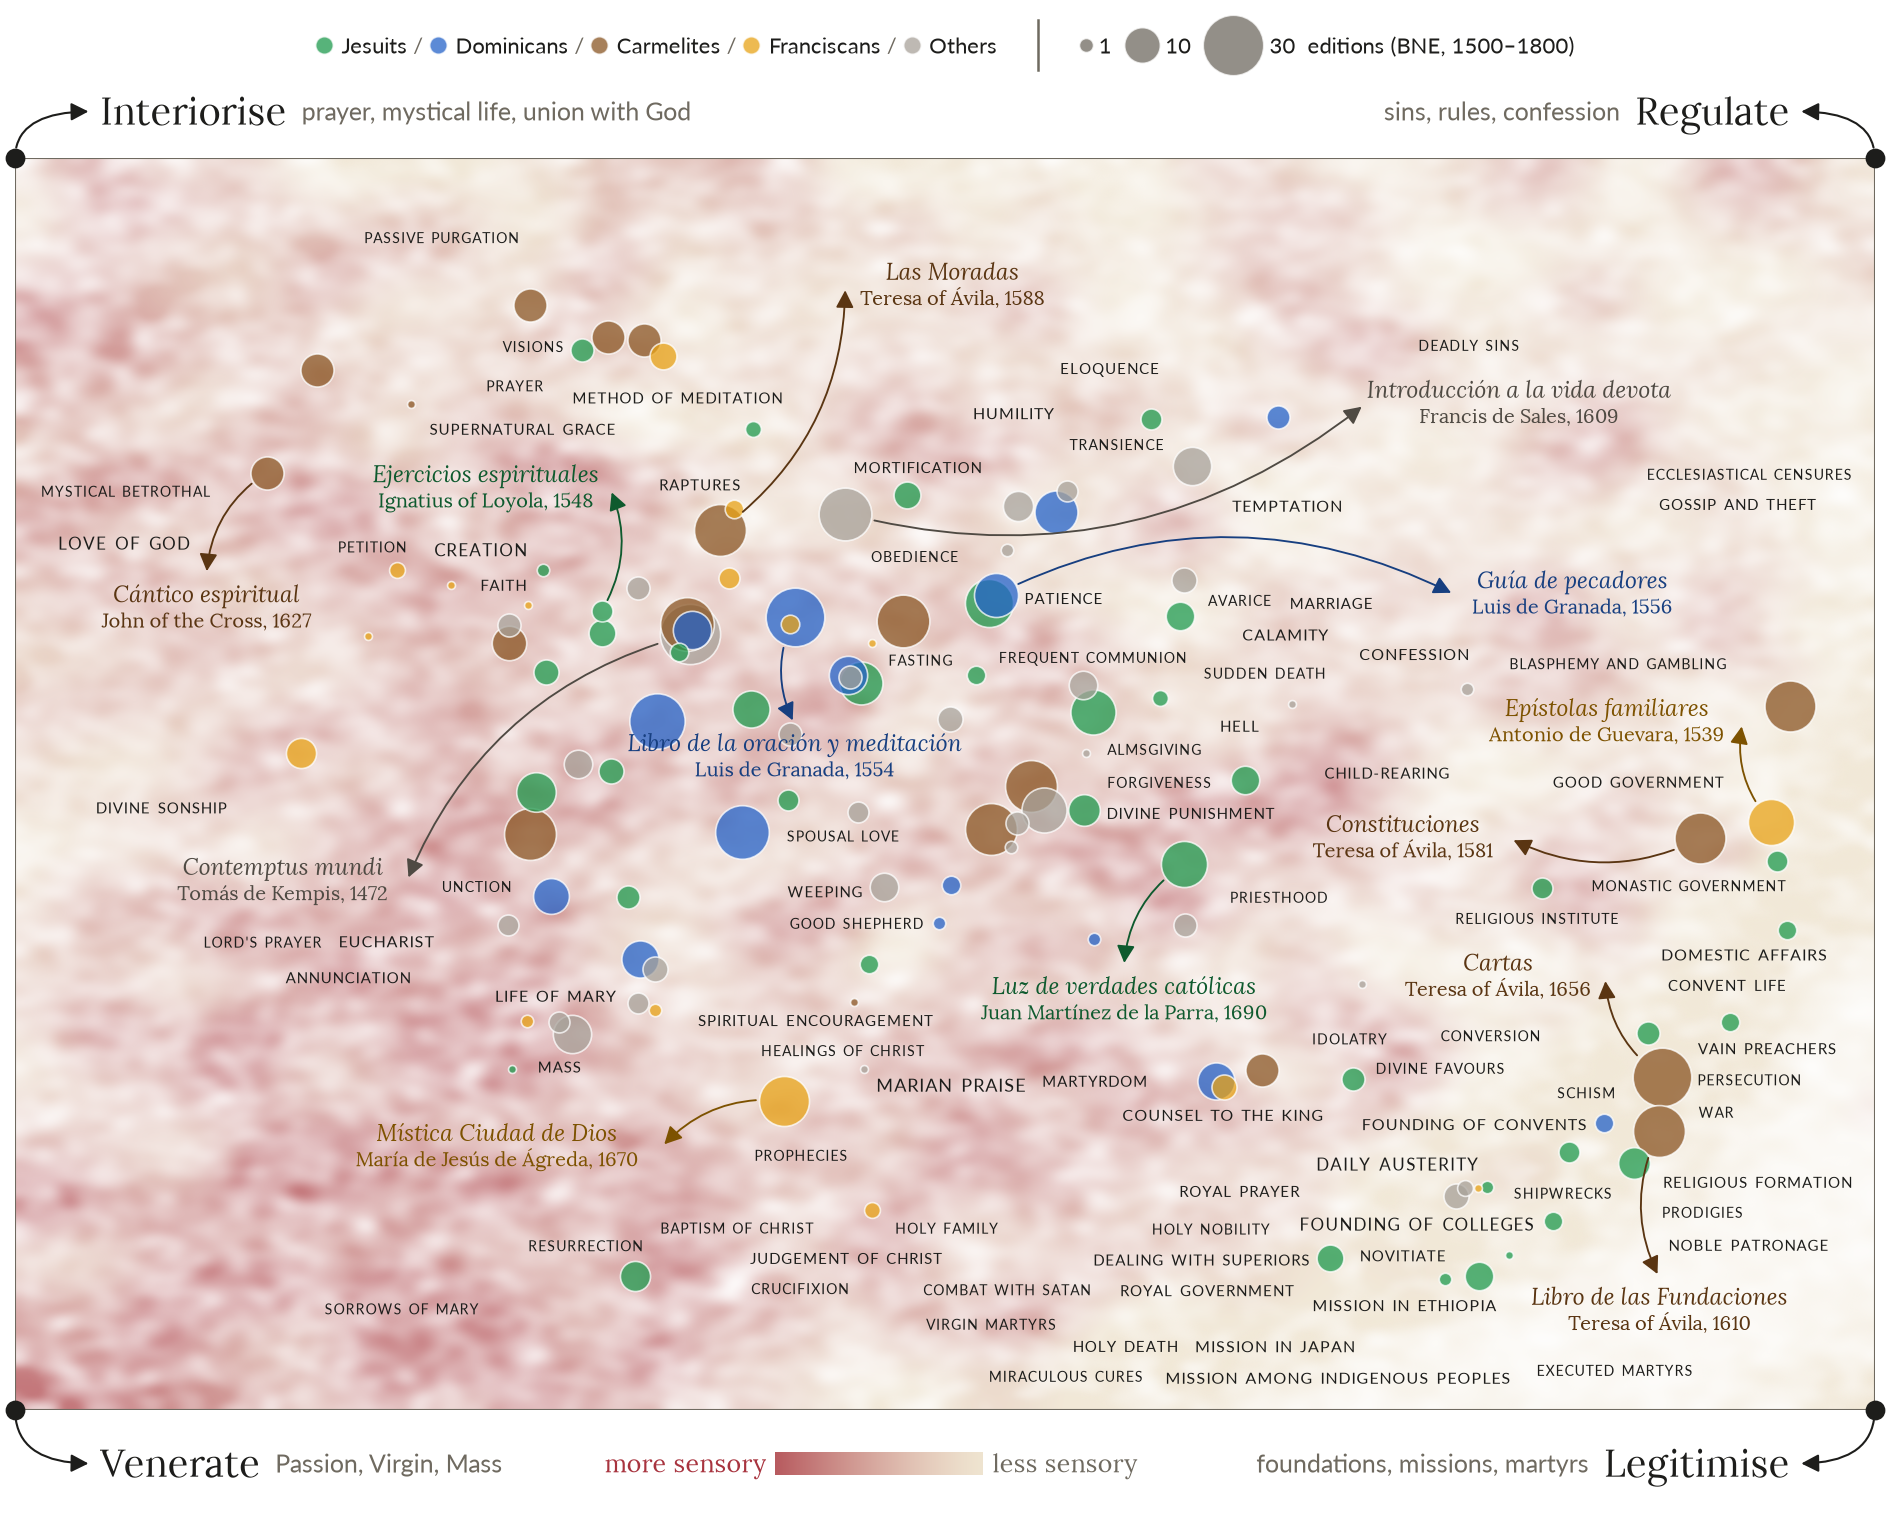

In [15]:
from IPython.display import Image
Image(name + ".png", width=900)